# 24. 생산계획일 = 로트로 볼 수 있나 (CN7·RG3)

**질문**: `PART_FACT_PLAN_DATE`(생산계획일)를 로트(작업일 묶음)로 써도 되는가

| # | 점검 | 통과 조건 |
|---|---|---|
| A1 | 날짜 경계 규칙 | 'h시 이후 생산 = 다음 날 작업분' 하나로 모든 샷 설명 |
| A2 | 로트 간 겹침 | 같은 설비에서 두 로트가 번갈아 생산되지 않음 (CN7·RG3 함께) |
| A3 | 경계 = 생산 정지 | 로트가 바뀌는 지점에 60분 넘는 공백 |
| B | Run ↔ 로트 | Run 하나가 두 로트에 걸치지 않음 |
| C | 공정 동질성 | 로트 안 Run끼리 상태 변수(금형·호퍼 온도, 계량 위치) η² < 0.5 |
| D | 품질 (참고) | 로트 간 불량률 차이 — 순열검정 |
| E | 최종 모델 (참고) | 로트별 양품 경보율(pct ≥ 0.99)이 기대 1%와 비슷한가 |

- 입력: `base/base_rows.csv` (00 출력), `outputs/final_model/{p}_scores.csv` (20a·20b 출력, 없으면 E 생략)
- 코드: `lot_check.py` · 기준값(60분, η² 0.5, q 0.99)은 결과 보기 전에 고정
- 라벨은 D에서만 사용
- **주의**: A1~B가 통과해도 확인되는 것은 '작업일 기준 묶음'까지. 실제 출하 로트였는지는 데이터로 증명 불가


In [1]:
%load_ext autoreload
%autoreload 2
import os
import pandas as pd
from lot_check import run_all, plot_lot_timeline
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)

OUT = './outputs/lot'
PRIMARY = '../../1. 사출성형기 AI 데이터셋/dataset/labeled_data.csv'   # 원본 형식 확인용 (없으면 자동 생략)
RES = run_all(out_dir=OUT, primary_path=PRIMARY if os.path.exists(PRIMARY) else None)

print('LH·RH 생산계획일이 서로 다른 샷:', RES['n_mismatch'], '(0이어야 정상)')
print(RES['S'].groupby('product').agg(샷=('lot', 'size'), 로트=('lot', 'nunique'), Run=('run_id', 'nunique')))

LH·RH 생산계획일이 서로 다른 샷: 0 (0이어야 정상)
            샷  로트  Run
product               
cn7      1979   6    6
rg3       627   4    6


## 종합 판정

In [2]:
display(RES['VERDICT'])

,기준,결과,판정
0,A1 날짜 경계가 한 규칙으로 설명됨,일치율 1.0000 (기준 9~23시),통과
1,A2 로트끼리 시간 겹침 없음 (설비 공통),"겹침 0쌍, 전환 9회 (겹침 없으면 9회)",통과
2,A3 로트 경계에 60분 넘는 정지,경계 8개 중 연속 생산 중 경계 0개,통과
3,B Run이 한 로트 안에만 있음,두 로트에 걸친 Run 0개,통과
4,C 로트 안 Run 간 상태 변수 η² < 0.5,"η² ≥ 0.5인 (로트, 변수) 4 / 6",확인
5,D 로트 간 불량률 차이 (참고),cn7 p=0.000; rg3 p=0.001,참고


## 로트 요약 + 생산 구간 그림
x축 = 생산계획일 0시 기준 경과 시간 (음수 = 전날 밤). 막대 색 = Run, 빨간 점 = 공정 불량

C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_636\2306973595.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(RES['LOT'].round(3))


,product,lot,시작,끝,길이(시간),샷,Run 수,Run,내부 최대 공백(분),60분 초과 공백,공정불량,불량률,초기허용
0,cn7,cn7_10-16,2020-10-16 04:57:47,2020-10-16 08:05:18,3.125,188,1,cn7_R1,2.017,0,14,0.074,0
1,cn7,cn7_10-20,2020-10-19 23:24:46,2020-10-20 06:20:14,6.924,418,1,cn7_R2,1.983,0,0,0.000,0
2,cn7,cn7_10-27,2020-10-27 00:10:40,2020-10-27 05:48:36,5.632,314,1,cn7_R3,10.883,0,0,0.000,5
3,cn7,cn7_10-29,2020-10-29 04:34:20,2020-10-29 07:58:43,3.406,189,1,cn7_R4,13.917,0,0,0.000,0
4,cn7,cn7_10-30,2020-10-29 23:25:39,2020-10-30 07:36:02,8.173,407,1,cn7_R5,59.483,0,0,0.000,0
5,cn7,cn7_11-03,2020-11-03 00:38:12,2020-11-03 08:19:35,7.690,463,1,cn7_R6,2.000,0,1,0.002,0
6,rg3,rg3_10-21,2020-10-21 00:16:26,2020-10-21 00:57:37,0.686,41,1,rg3_R1,1.050,0,0,0.000,0
7,rg3,rg3_10-22,2020-10-22 00:24:05,2020-10-22 08:09:24,7.755,300,2,"rg3_R2, rg3_R3",140.000,1,15,0.050,0
8,rg3,rg3_10-23,2020-10-23 01:01:28,2020-10-23 07:46:03,6.743,250,2,"rg3_R4, rg3_R5",125.617,1,10,0.040,0
9,rg3,rg3_11-04,2020-11-04 05:01:17,2020-11-04 05:43:29,0.703,36,1,rg3_R6,4.133,0,7,0.194,0


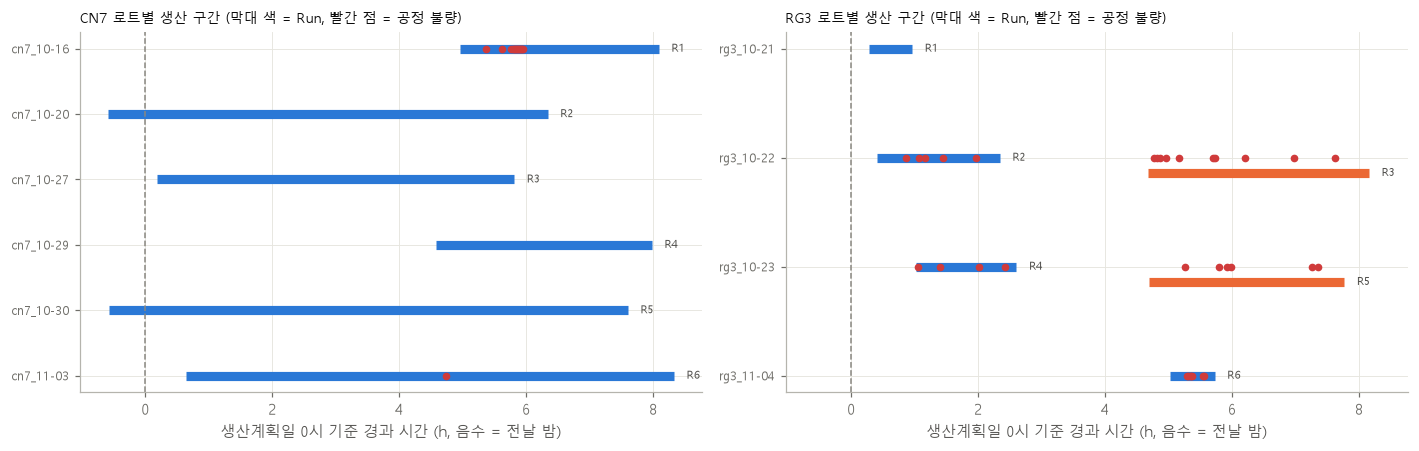

In [3]:
display(RES['LOT'].round(3))
plot_lot_timeline(RES['S'], save=f'{OUT}/lot_timeline.png');

## A1. 날짜 경계 규칙

In [4]:
display(RES['OFFSET'])                                   # 계획일 − 실제 날짜(일)별 생산 시각 범위
c = RES['CUT']
display(c[c['일치율'] == c['일치율'].max()])               # 일치율 최고인 기준 시각 범위

,product,차이_일,샷,최소,최대
0,cn7,0,1910,0,8
1,cn7,1,69,23,23
2,rg3,0,627,0,8


,기준 시각(시),일치율,불일치 샷
8,9,1.0,0
9,10,1.0,0
10,11,1.0,0
11,12,1.0,0
12,13,1.0,0
13,14,1.0,0
14,15,1.0,0
15,16,1.0,0
16,17,1.0,0
17,18,1.0,0


## A2. 로트 간 겹침 · A3. 로트 경계의 공백

In [5]:
display(RES['OV'])
display(RES['BD'].round(1))

,lot A,lot B,겹침(분)


C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_636\1196680426.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(RES['BD'].round(1))


,product,이전 lot,다음 lot,이전 마지막 샷,다음 첫 샷,공백(분),Run도 바뀜
0,cn7,cn7_10-16,cn7_10-20,2020-10-16 08:05:18,2020-10-19 23:24:46,5239.5,True
1,cn7,cn7_10-20,cn7_10-27,2020-10-20 06:20:14,2020-10-27 00:10:40,9710.4,True
2,cn7,cn7_10-27,cn7_10-29,2020-10-27 05:48:36,2020-10-29 04:34:20,2805.7,True
3,cn7,cn7_10-29,cn7_10-30,2020-10-29 07:58:43,2020-10-29 23:25:39,926.9,True
4,cn7,cn7_10-30,cn7_11-03,2020-10-30 07:36:02,2020-11-03 00:38:12,5342.2,True
5,rg3,rg3_10-21,rg3_10-22,2020-10-21 00:57:37,2020-10-22 00:24:05,1406.5,True
6,rg3,rg3_10-22,rg3_10-23,2020-10-22 08:09:24,2020-10-23 01:01:28,1012.1,True
7,rg3,rg3_10-23,rg3_11-04,2020-10-23 07:46:03,2020-11-04 05:01:17,17115.2,True


## B. Run ↔ 로트 대응

In [6]:
CT = RES['CT']
display(CT.loc[:, (CT > 0).any()])
print('두 로트에 걸친 Run:', RES['run_purity'][RES['run_purity'] < 1].index.tolist())
print('Run 2개 이상인 로트:', RES['lot_runs'][RES['lot_runs'] > 1].to_dict())

lot,cn7_10-16,cn7_10-20,cn7_10-27,cn7_10-29,cn7_10-30,cn7_11-03,rg3_10-21,rg3_10-22,rg3_10-23,rg3_11-04
run_id,,,,,,,,,,
cn7_R1,188,0,0,0,0,0,0,0,0,0
cn7_R2,0,418,0,0,0,0,0,0,0,0
cn7_R3,0,0,314,0,0,0,0,0,0,0
cn7_R4,0,0,0,189,0,0,0,0,0,0
cn7_R5,0,0,0,0,407,0,0,0,0,0
cn7_R6,0,0,0,0,0,463,0,0,0,0
rg3_R1,0,0,0,0,0,0,41,0,0,0
rg3_R2,0,0,0,0,0,0,0,103,0,0
rg3_R3,0,0,0,0,0,0,0,197,0,0


두 로트에 걸친 Run: []
Run 2개 이상인 로트: {'rg3_10-22': 2, 'rg3_10-23': 2}


## C. 공정 동질성
- C-1: 변동 중 로트 평균 차이 / Run 평균 차이의 비중 (로트 ≈ Run이면 둘이 비슷)
- C-2: **Run이 2개 이상인 로트**(RG3 10/22, 10/23 예상) 안에서 Run끼리 조건이 다른가 → 상태 변수 η² ≥ 0.5면 로트보다 Run이 분석 단위로 적합

In [7]:
display(RES['ETA'].round(3))
display(RES['WITHIN'].round(3))

,product,변수,구분,η² (로트),η² (Run)
0,cn7,금형온도3,상태,0.646,0.646
1,cn7,호퍼온도,상태,0.718,0.718
2,cn7,계량위치,상태,0.994,0.994
3,cn7,사출속도,이벤트,0.339,0.339
4,cn7,충전시간,이벤트,0.122,0.122
5,cn7,사출압,이벤트,0.481,0.481
6,cn7,쿠션,이벤트,0.750,0.750
7,cn7,배압,이벤트,0.045,0.045
8,cn7,배럴4,이벤트,0.001,0.001
9,rg3,금형온도3,상태,0.291,0.938


,lot,변수,구분,Run별 평균,Run 간 η² (로트 안),Kruskal p
0,rg3_10-22,금형온도3,상태,"{'rg3_R2': 21.95, 'rg3_R3': 22.73}",0.865,0.000
1,rg3_10-22,호퍼온도,상태,"{'rg3_R2': 65.98, 'rg3_R3': 66.44}",0.146,0.000
2,rg3_10-22,계량위치,상태,"{'rg3_R2': 53.59, 'rg3_R3': 53.57}",0.573,0.000
3,rg3_10-22,사출속도,이벤트,"{'rg3_R2': 128.29, 'rg3_R3': 128.29}",0.001,0.512
4,rg3_10-22,충전시간,이벤트,"{'rg3_R2': 0.93, 'rg3_R3': 0.93}",0.012,0.062
5,rg3_10-22,사출압,이벤트,"{'rg3_R2': 142.56, 'rg3_R3': 142.56}",0.000,0.766
6,rg3_10-22,쿠션,이벤트,"{'rg3_R2': 654.26, 'rg3_R3': 654.26}",0.000,0.942
7,rg3_10-22,배압,이벤트,"{'rg3_R2': 60.61, 'rg3_R3': 60.66}",0.004,0.212
8,rg3_10-22,배럴4,이벤트,"{'rg3_R2': 275.37, 'rg3_R3': 275.37}",0.000,0.974
9,rg3_10-23,금형온도3,상태,"{'rg3_R4': 21.72, 'rg3_R5': 23.41}",0.931,0.000


## D. 품질 — 로트(또는 Run)마다 불량률이 다른가 (참고)
p가 작으면 불량이 특정 로트에 몰림. 로트 정의의 타당성과는 별개로, 로트 단위 품질 관리가 의미 있다는 근거

In [8]:
display(RES['QT'].round(4))

,product,단위,샷,불량,그룹 수,카이제곱,p(순열),불량 최다 그룹 비중
0,cn7,lot,1979,15,6,123.7706,0.0002,0.9333
1,cn7,run_id,1979,15,6,123.7706,0.0002,0.9333
2,rg3,lot,627,32,4,18.1272,0.0014,0.4688
3,rg3,run_id,627,32,6,18.5628,0.0040,0.3125


## E. 최종 모델 — 로트별 양품 경보율 (참고)
기대 경보율 1% (pct ≥ 0.99). 특정 로트만 크게 벗어나면 로트 단위 수준 이동 → 4장 '작업일 시작 시 기준 점검' 근거

In [9]:
A = RES['ALARM']
display(A.round(4) if len(A) else '최종 모델 점수 파일 없음 → 20a·20b 먼저 실행')

,lot,양품,경보,pct_중앙값,경보율,기대,이항 p
0,cn7_10-16,174,3,0.2495,0.0172,0.01,0.2530
1,cn7_10-20,418,4,0.3901,0.0096,0.01,1.0000
2,cn7_10-27,309,2,0.4153,0.0065,0.01,0.7752
3,cn7_10-29,189,5,0.3917,0.0265,0.01,0.0424
4,cn7_10-30,407,6,0.2569,0.0147,0.01,0.3107
5,cn7_11-03,462,6,0.3559,0.0130,0.01,0.4765
6,rg3_10-21,41,0,0.5289,0.0000,0.01,1.0000
7,rg3_10-22,285,7,0.5404,0.0246,0.01,0.0258
8,rg3_10-23,240,1,0.5081,0.0042,0.01,0.7377
9,rg3_11-04,29,1,0.8938,0.0345,0.01,0.2528


## (선택) 1차 원본 PART_FACT_PLAN_DATE 형식

In [10]:
print(RES['PRIMARY'])

{'원본 값 예시': ['2020-10-16 오전 12:00:00', '2020-10-20 오전 12:00:00', '2020-10-21 오전 12:00:00', '2020-10-22 오전 12:00:00', '2020-10-23 오전 12:00:00', '2020-10-27 오전 12:00:00', '2020-10-29 오전 12:00:00', '2020-10-30 오전 12:00:00'], '계획일 안 시리얼 시간순 증가 비율': 1.0}


## 해석 체크리스트
- **A1** 일치율 1.0 + 기준 시각 범위가 생산 공백 시간대(예: 9~23시)에 걸치면 → '야간 작업을 다음 날 작업분으로 기록'으로 해석
- **A2·A3·B** 모두 통과 → 생산계획일은 연속 가동 구간을 자르지 않는 작업일 묶음
- **C** RG3 로트 안 Run 간 금형온도 η²가 크면 → 로트 = 작업일, 공정 분석 단위 = Run으로 구분해서 서술
- **D·E**는 참고. 보고서에는 '작업일 기준 묶음으로 해석 가능'까지만 쓰고, 실제 출하 로트 여부는 확인 불가로 명시
